# Reliability Diagram

A function for plotting a reliability diagram (calibration curve) of a binary classifier.

In [1]:
from mlxtend.plotting import plot_reliability_diagram

## Overview

A reliability diagram shows whether a classifier's probabilities can be taken at face value. Predictions are grouped into probability bins; for each bin, the **mean predicted probability** (x-axis) is plotted against the **observed fraction of positives** (y-axis).

- A perfectly calibrated classifier lies on the dashed diagonal.
- Points **below** the diagonal: the model is over-confident.
- Points **above** the diagonal: the model is under-confident.

The legend shows the expected calibration error (ECE), and a small histogram below the diagram shows how many predictions fall into each bin, so that you can tell which parts of the curve are based on many samples and which on few.

### References

- Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. *ICML*.
- Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *ICML*.

## Example 1 - A single classifier

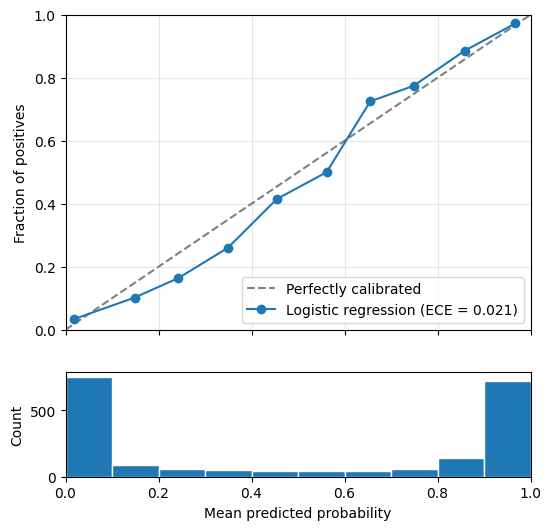

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(
    n_samples=8000, n_features=20, n_informative=5, n_redundant=10, random_state=123
)
# 3-way split: the calibrator must be fit on data the classifier has not seen
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.5, random_state=123)
X_cal, X_test, y_cal, y_test = train_test_split(X_rest, y_rest, test_size=0.5, random_state=123)

import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000).fit(X_train, y_train)
p_lr = lr.predict_proba(X_test)[:, 1]

fig, ax = plot_reliability_diagram(y_test, p_lr, label="Logistic regression", figsize=(6, 6))
plt.show()

## Example 2 - Comparing several classifiers

Pass the same `ax` to overlay more models. The diagonal is only drawn once.

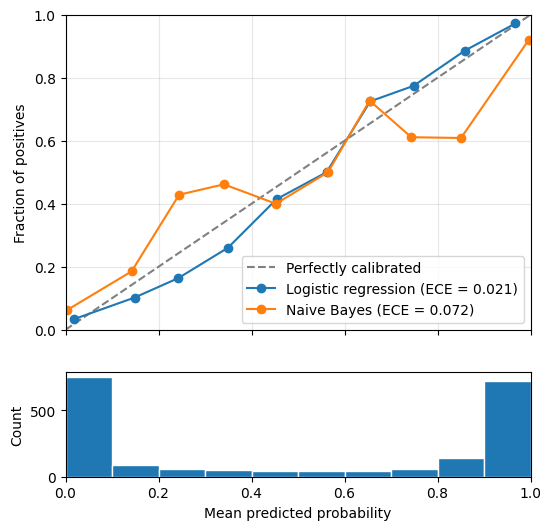

In [3]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB().fit(X_train, y_train)
p_nb = nb.predict_proba(X_test)[:, 1]

fig, ax = plot_reliability_diagram(y_test, p_lr, label="Logistic regression", figsize=(6, 6))
plot_reliability_diagram(y_test, p_nb, label="Naive Bayes", ax=ax)
plt.show()

## Example 3 - Without the histogram and with fewer bins

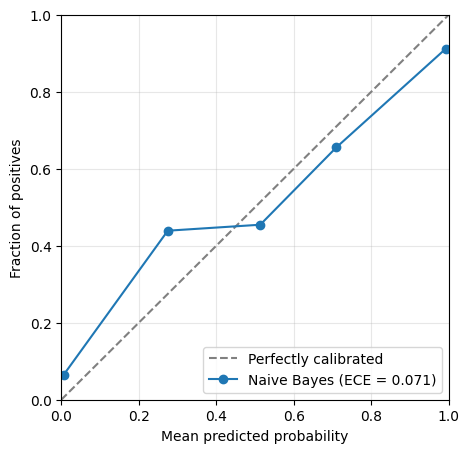

In [4]:
fig, ax = plot_reliability_diagram(
    y_test, p_nb, n_bins=5, label="Naive Bayes", show_histogram=False, figsize=(5, 5)
)
plt.show()

## API

See the function docstring (`help(plot_reliability_diagram)`) for the full parameter list.